In [6]:
%pip install pandas numpy matplotlib seaborn scikit-learn scipy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
print("Hello")

Hello


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [10]:
%pip install ucimlrepo


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [11]:
from ucimlrepo import fetch_ucirepo

# Fetch Student Academics Performance dataset
student_data = fetch_ucirepo(id=467)

# Separate features and target
X = student_data.data.features
y = student_data.data.targets

print("Dataset loaded successfully!")
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Dataset loaded successfully!
Features shape: (131, 22)


AttributeError: 'NoneType' object has no attribute 'shape'

In [18]:
print("Features:")
display(X.head())

print("\nColumn names:")
print(X.columns.tolist())

print("\nDataset information:")
print(X.info())

Features:


,ge,cst,tnp,twp,iap,esp,arr,ms,ls,as,...,fs,fq,mq,fo,mo,nf,sh,ss,me,tt
0,F,G,Good,Good,Vg,Good,Y,Unmarried,V,Paid,...,Average,Um,10,Farmer,Housewife,Large,Poor,Govt,Asm,Small
1,M,OBC,Vg,Vg,Vg,Vg,N,Unmarried,V,Paid,...,Average,Um,Il,Service,Service,Small,Poor,Govt,Asm,Average
2,F,OBC,Good,Good,Vg,Good,N,Unmarried,V,Paid,...,Average,12,10,Service,Housewife,Average,Average,Govt,Asm,Large
3,M,MOBC,Pass,Good,Vg,Good,N,Unmarried,V,Paid,...,Small,12,Um,Business,Business,Large,Poor,Govt,Asm,Average
4,M,G,Good,Good,Vg,Vg,N,Unmarried,V,Paid,...,Average,10,12,Service,Housewife,Large,Poor,Private,Asm,Small



Column names:
['ge', 'cst', 'tnp', 'twp', 'iap', 'esp', 'arr', 'ms', 'ls', 'as', 'fmi', 'fs', 'fq', 'mq', 'fo', 'mo', 'nf', 'sh', 'ss', 'me', 'tt']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 131 entries, 0 to 130
Data columns (total 21 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   ge      131 non-null    str  
 1   cst     131 non-null    str  
 2   tnp     131 non-null    str  
 3   twp     131 non-null    str  
 4   iap     131 non-null    str  
 5   esp     131 non-null    str  
 6   arr     131 non-null    str  
 7   ms      131 non-null    str  
 8   ls      131 non-null    str  
 9   as      131 non-null    str  
 10  fmi     131 non-null    str  
 11  fs      131 non-null    str  
 12  fq      131 non-null    str  
 13  mq      131 non-null    str  
 14  fo      131 non-null    str  
 15  mo      131 non-null    str  
 16  nf      131 non-null    str  
 17  sh      131 non-null    str  
 18  ss      131 non-null    str  


In [19]:


y = X['atd']
X = X.drop('atd', axis=1)

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget values:")
print(y.value_counts())

KeyError: 'atd'

In [35]:

print("Missing values in each column:")
print(X.isnull().sum())

print("\nNumber of duplicate rows:", X.duplicated().sum())

# Check target for missing values
print("\nMissing target values:", y.isnull().sum())

Missing values in each column:
ge     0
cst    0
tnp    0
twp    0
iap    0
esp    0
arr    0
ms     0
ls     0
as     0
fmi    0
fs     0
fq     0
mq     0
fo     0
mo     0
nf     0
sh     0
ss     0
me     0
tt     0
dtype: int64

Number of duplicate rows: 0

Missing target values: 0


In [21]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

X_encoded = encoder.fit_transform(X)

print("Original features:", X.shape)
print("Encoded features:", X_encoded.shape)

Original features: (131, 21)
Encoded features: (131, 75)


In [22]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (104, 75)
Testing data: (27, 75)


In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

lr = LogisticRegression(max_iter=1000)

lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr, average='weighted', zero_division=0))
print("Recall:", recall_score(y_test, y_pred_lr, average='weighted', zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred_lr, average='weighted', zero_division=0))

Accuracy: 0.6296296296296297
Precision: 0.6283068783068784
Recall: 0.6296296296296297
F1 Score: 0.6201166456920932


In [24]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(random_state=42)

dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print("Precision:", precision_score(y_test, y_pred_dt, average='weighted', zero_division=0))
print("Recall:", recall_score(y_test, y_pred_dt, average='weighted', zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred_dt, average='weighted', zero_division=0))

Accuracy: 0.3333333333333333
Precision: 0.31478315922760375
Recall: 0.3333333333333333
F1 Score: 0.32208045365940097


In [25]:
from sklearn.svm import SVC

svm = SVC()

svm.fit(X_train, y_train)

y_pred_svm = svm.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_svm))
print("Precision:", precision_score(y_test, y_pred_svm, average='weighted', zero_division=0))
print("Recall:", recall_score(y_test, y_pred_svm, average='weighted', zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred_svm, average='weighted', zero_division=0))

Accuracy: 0.5185185185185185
Precision: 0.3877995642701525
Recall: 0.5185185185185185
F1 Score: 0.4391534391534392


In [26]:
models = {
    "Logistic Regression": y_pred_lr,
    "Decision Tree": y_pred_dt,
    "SVM": y_pred_svm
}

for name, predictions in models.items():
    print(name)
    print("Accuracy:", round(accuracy_score(y_test, predictions), 4))
    print("Precision:", round(precision_score(y_test, predictions, average='weighted', zero_division=0), 4))
    print("Recall:", round(recall_score(y_test, predictions, average='weighted', zero_division=0), 4))
    print("F1 Score:", round(f1_score(y_test, predictions, average='weighted', zero_division=0), 4))
    print()

Logistic Regression
Accuracy: 0.6296
Precision: 0.6283
Recall: 0.6296
F1 Score: 0.6201

Decision Tree
Accuracy: 0.3333
Precision: 0.3148
Recall: 0.3333
F1 Score: 0.3221

SVM
Accuracy: 0.5185
Precision: 0.3878
Recall: 0.5185
F1 Score: 0.4392



[[4 3 3]
 [1 9 1]
 [2 0 4]]


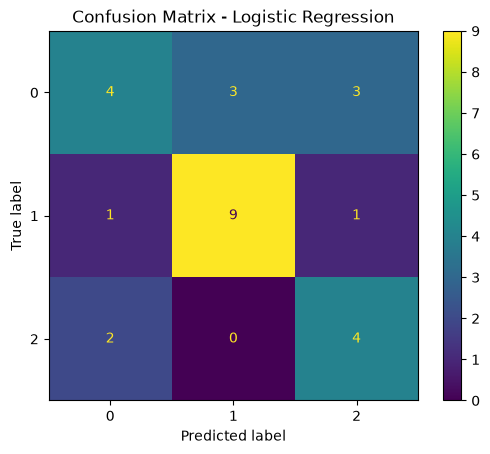

In [27]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_lr)

print(cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

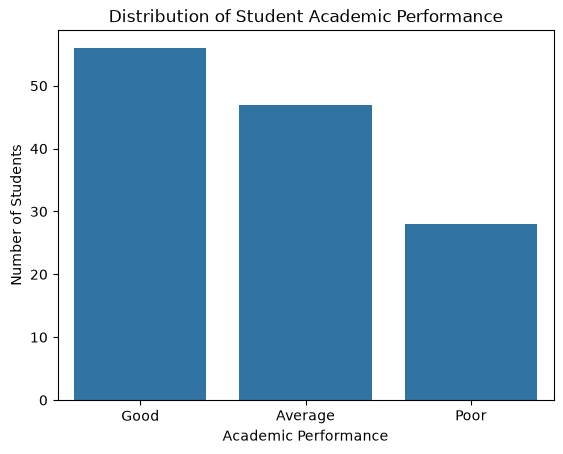

In [28]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x=y)
plt.title("Distribution of Student Academic Performance")
plt.xlabel("Academic Performance")
plt.ylabel("Number of Students")
plt.show()

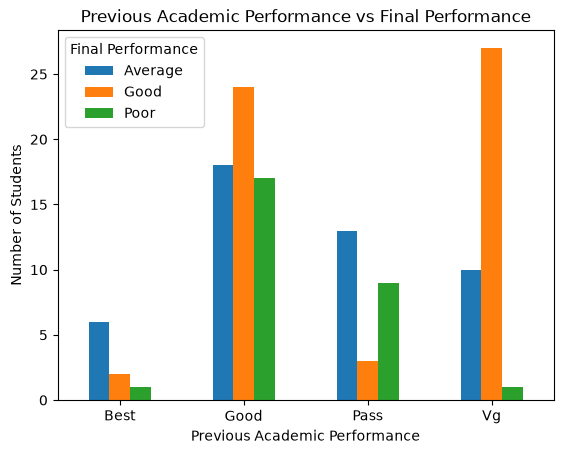

In [39]:
pd.crosstab(X['tnp'], y).plot(kind='bar')
plt.title("Previous Academic Performance vs Final Performance")
plt.xlabel("Previous Academic Performance")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.legend(title="Final Performance")
plt.show() 

In [30]:
from scipy.stats import chi2_contingency

table = pd.crosstab(X['tnp'], y)
chi2, p_value, dof, expected = chi2_contingency(table)

print("Chi-Square Statistic:", round(chi2, 4))
print("P-value:", round(p_value, 4))

if p_value < 0.05:
    print("There is a significant relationship between previous and final academic performance.")
else:
    print("There is no statistically significant relationship between previous and final academic performance.")

Chi-Square Statistic: 29.9472
P-value: 0.0
There is a significant relationship between previous and final academic performance.


In [31]:
from sklearn.metrics import roc_auc_score, log_loss

y_proba_lr = lr.predict_proba(X_test)

auc_lr = roc_auc_score(
    y_test,
    y_proba_lr,
    multi_class='ovr',
    average='weighted'
)

loss_lr = log_loss(y_test, y_proba_lr)

print("ROC-AUC Score:", round(auc_lr, 4))
print("Log Loss:", round(loss_lr, 4))


ROC-AUC Score: 0.8475
Log Loss: 0.8015


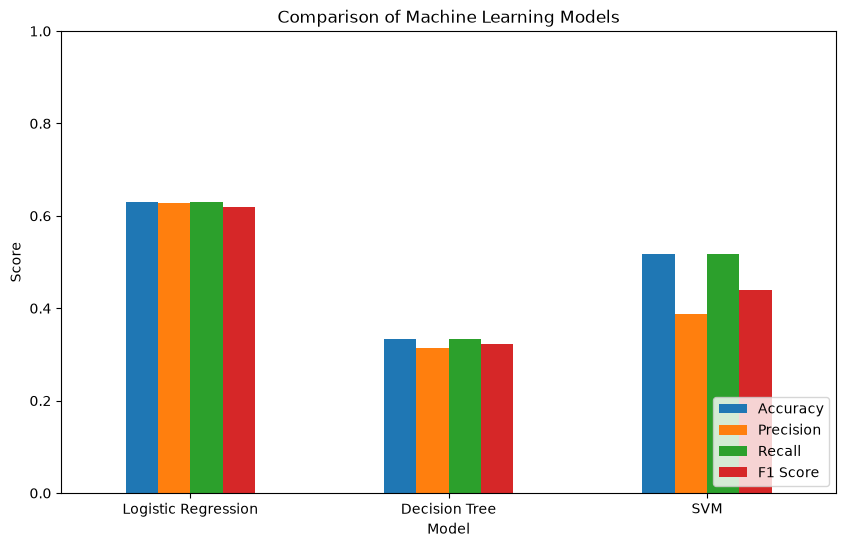

In [32]:
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree', 'SVM'],
    'Accuracy': [0.6296, 0.3333, 0.5185],
    'Precision': [0.6283, 0.3148, 0.3878],
    'Recall': [0.6296, 0.3333, 0.5185],
    'F1 Score': [0.6201, 0.3221, 0.4392]
})

results.set_index('Model').plot(kind='bar', figsize=(10, 6))
plt.title("Comparison of Machine Learning Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.show()

In [33]:
results

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.6296,0.6283,0.6296,0.6201
1,Decision Tree,0.3333,0.3148,0.3333,0.3221
2,SVM,0.5185,0.3878,0.5185,0.4392


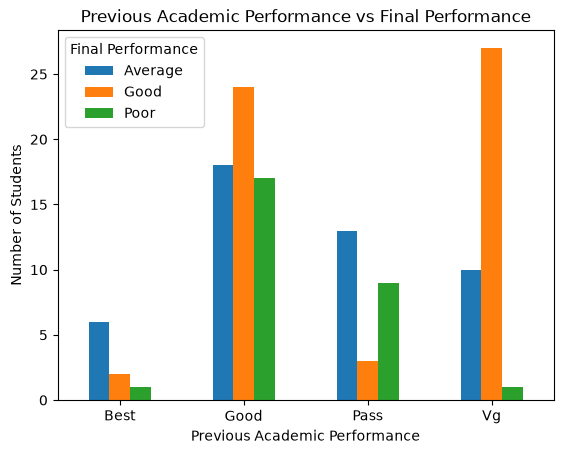

In [41]:
pd.crosstab(X['tnp'], y).plot(kind='bar')
plt.title("Previous Academic Performance vs Final Performance")
plt.xlabel("Previous Academic Performance")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.legend(title="Final Performance")
plt.show() 